# Phase 2: rules engine

Runs the policy engine (`configs/policy_phase2.yaml`) on the validation set, scores it, and checks validity, audit
coverage, research fields, date intervals, UIDs and repeatability independently of the scorer.

In [1]:
import os
import json
import time
import shutil
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom
import yaml

from fpdeid import paths
from fpdeid import engine
from fpdeid import scoring
from fpdeid import validity
from fpdeid import checks

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

phase_results = os.path.join(paths.RESULTS, "phase2")
os.makedirs(phase_results, exist_ok=True)

file_table = pd.read_csv(os.path.join(paths.DERIVED, "validation_file_table.csv"), dtype=str)
all_files = file_table["path"].tolist()
answer_db = os.path.join(paths.VALIDATION_ANSWER_DIR, "MIDI-B-Answer-Key-Validation.db")
print("files:", len(all_files))

files: 23921


## 1. The policy

In [2]:
policy_path = os.path.join(paths.CONFIGS, "policy_phase2.yaml")
policy = engine.Policy(policy_path, paths.VALIDATION_UID_MAP, paths.VALIDATION_PATIENT_MAP)
print(policy.name)
print("options:", policy.options)

rule_actions = pd.Series([rule[0] for rule in policy.rules.values()]).value_counts()
print("standard attributes with an explicit rule:", len(policy.rules))
rule_actions

FP-DeID policy v2.0 (rules only)
options: ['retain_patient_chars', 'retain_long_modified_dates']
standard attributes with an explicit rule: 653


X    299
C    174
D     70
U     57
Z     39
K     14
Name: count, dtype: int64

In [3]:
# policy coverage: how many tag paths of the data are handled by an explicit rule (not by the default "keep")?
tag_census = pd.read_csv(os.path.join(paths.RESULTS, "phase1", "tag_census.csv"))
top_standard = tag_census[(tag_census["private"] == False) & (tag_census["depth"] == 0)]

explicit = 0
default_keep = []
for path_text in top_standard["path"]:
    tag_int = int(path_text.strip("()").replace(",", ""), 16)
    in_rules = tag_int in policy.rules or tag_int in policy.overrides or tag_int in policy.keep_and_clean
    if in_rules:
        explicit = explicit + 1
    else:
        default_keep.append(path_text)

print("top-level standard tags in the data:", len(top_standard))
print("handled by an explicit rule        :", explicit)
print("kept by default (not in PS3.15)    :", len(default_keep))
print("private tags: all handled by the value-type rule")

top-level standard tags in the data: 439
handled by an explicit rule        : 132
kept by default (not in PS3.15)    : 307
private tags: all handled by the value-type rule


## 2. Clean the whole validation set

In [4]:
out_folder = os.path.join(paths.OUTPUTS, "phase2")
shutil.rmtree(out_folder, ignore_errors=True)

start = time.time()
run_table = engine.run(all_files, out_folder, policy, workers=16)
seconds = time.time() - start

n_errors = (run_table["error"] != "").sum()
n_studies = file_table["study_uid"].nunique()
print("files:", len(run_table), "errors:", n_errors)
print("time:", round(seconds, 1), "s =", round(len(run_table) / seconds), "files/s =",
      round(n_studies / seconds * 3600), "studies/hour")

action_totals = run_table.filter(like="n_").sum().astype(int)
action_totals

files: 23921 errors: 0
time: 17.7 s = 1354 files/s = 49118 studies/hour


n_P    275751
n_S    240307
n_Z    173547
n_X    502244
n_D    110756
n_A     89021
n_T        68
dtype: int64

## 3. Official MIDI-B score

In [5]:
start = time.time()
db_path = scoring.run_official_scorer("phase2", out_folder, answer_db,
                                      paths.VALIDATION_UID_MAP, paths.VALIDATION_PATIENT_MAP,
                                      os.path.join(paths.DERIVED, "scorer_runs"), cpus=16)
print("scored in", round(time.time() - start), "s")
results = scoring.add_categories(scoring.load_results(db_path))

summary = scoring.summarise(results)
summary.update(scoring.privacy_utility(results))

baseline_table = pd.read_csv(os.path.join(paths.RESULTS, "phase1", "baseline_scores.csv"), index_col=0)
compare = baseline_table[["BA", "BB"]].copy()
compare["Phase 2"] = pd.Series(summary)
compare = compare.loc[list(summary.keys())]
compare.to_csv(os.path.join(phase_results, "scores_vs_baselines.csv"))
compare

scored in 449 s


,BA,BB,Phase 2
checks,6173204.000,6173204.000,6173204.000
plain_accuracy_%,72.594,75.875,95.030
hipaa_checks,567859.000,567859.000,567859.000
hipaa_accuracy_%,99.989,99.988,99.994
dicom_checks,1977969.000,1977969.000,1977969.000
dicom_accuracy_%,99.885,99.885,100.000
tcia_checks,3627376.000,3627376.000,3627376.000
tcia_accuracy_%,53.424,59.007,91.543
weighted_score_%,95.311,95.870,99.150
privacy_checks,717810.000,717810.000,717810.000


In [6]:
per_action = scoring.per_action(results)
per_action.to_csv(os.path.join(phase_results, "per_action.csv"))
per_action

,checks,passed,failed,accuracy_%
action,,,,
<date_shifted>,139774,139774.0,0.0,100.000
<patid_consistent>,23921,23921.0,0.0,100.000
<pixels_hidden>,35,6.0,29.0,17.143
<pixels_retained>,23886,23886.0,0.0,100.000
<tag_retained>,1101091,1101090.0,1.0,100.000
<text_notnull>,618539,618539.0,0.0,100.000
<text_removed>,343583,339035.0,4548.0,98.676
<text_retained>,3453539,3151330.0,302209.0,91.249
<uid_changed>,234418,234418.0,0.0,100.000


In [7]:
results["passed"] = results["check_passed"].fillna(0).astype(float)
per_modality = (results.groupby("modality")["passed"].mean() * 100).round(3)
per_modality.to_csv(os.path.join(phase_results, "per_modality.csv"))
per_modality

modality
<CR>    96.979
<CT>    95.896
<DX>    97.327
<MG>    99.766
<MR>    93.330
<PT>    95.134
<SR>    99.870
<US>    93.740
Name: passed, dtype: float64

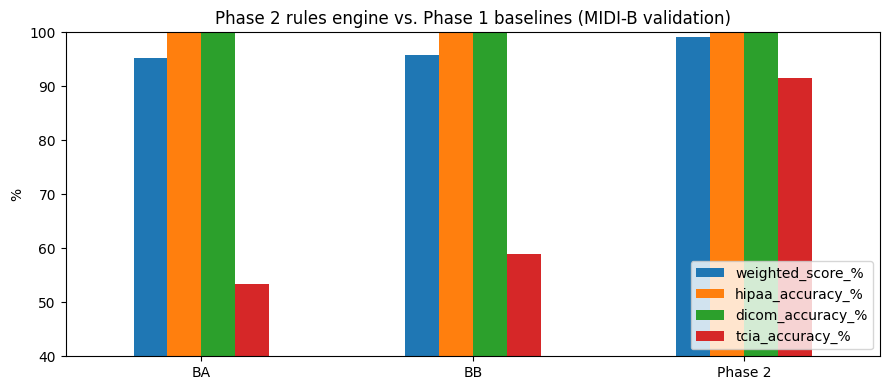

In [8]:
plot_table = compare.loc[["weighted_score_%", "hipaa_accuracy_%", "dicom_accuracy_%", "tcia_accuracy_%"]].astype(float).T
plot_table.plot(kind="bar", figsize=(9, 4), ylim=(40, 100))
plt.ylabel("%")
plt.title("Phase 2 rules engine vs. Phase 1 baselines (MIDI-B validation)")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(phase_results, "scores_vs_baselines.png"), dpi=120)
plt.show()

### Accuracy on "keep" checks (over-cleaning)

In [9]:
keep_actions = ["<text_retained>", "<tag_retained>", "<text_notnull>", "<pixels_retained>"]
keep_rows = results[results["action"].isin(keep_actions)]
keep_accuracy = 100 * keep_rows["passed"].mean()
print("keep-check accuracy:", round(keep_accuracy, 3), "%")

keep-check accuracy: 94.185 %


## 4. Independent checks: validity, audit coverage, utility, dates, UIDs

In [10]:
# DICOM validity on ALL files: no new dciodvfy error compared with the input
ok = run_table[run_table["error"] == ""]
pairs = list(zip(ok["input"], ok["output"]))
start = time.time()
valid_table = validity.check_pairs(pairs, workers=24)
print("validity checked in", round(time.time() - start), "s")
valid_pct = 100 * (valid_table["new_errors"] == 0).mean()
print("valid files (no new error):", round(valid_pct, 3), "%")

new_error_types = valid_table[valid_table["new_errors"] > 0]["new_error_examples"].str.split(r" \|\| ").explode()
new_error_types = new_error_types.str.replace(r"\[\d+\]", "", regex=True)
new_error_types.value_counts().head(10)

validity checked in 40 s
valid files (no new error): 100.0 %


Series([], Name: count, dtype: int64)

In [11]:
# read the audit log: which tag paths were logged for each file
audited = {}
with open(os.path.join(out_folder, "audit.jsonl")) as f:
    for line in f:
        record = json.loads(line)
        logged_paths = set()
        for change in record["changes"]:
            logged_paths.add(change["tag"])
        audited[record["input"]] = logged_paths

uid_map = pd.read_csv(paths.VALIDATION_UID_MAP, dtype=str)
input_uids = set(uid_map["id_old"])

jobs = []
for input_path, output_path in pairs:
    jobs.append((input_path, output_path, audited[input_path]))

start = time.time()
check_rows = checks.run_checks(jobs, input_uids, workers=16)
check_table = pd.DataFrame(check_rows)
print("checked in", round(time.time() - start), "s")

checked in 17 s


In [12]:
independent = {}
changed_total = check_table["changed_paths"].sum()
not_logged_total = check_table["changed_not_logged"].sum()
independent["audit coverage %"] = round(100 * (1 - not_logged_total / changed_total), 4)
independent["changes found by diff"] = int(changed_total)
independent["changes not in audit log"] = int(not_logged_total)

present = check_table["utility_present"].sum()
kept = check_table["utility_kept"].sum()
independent["research fields kept %"] = round(100 * kept / present, 4)

date_pairs = check_table["date_pairs"].sum()
date_same = check_table["date_pairs_same"].sum()
independent["date intervals kept %"] = round(100 * date_same / date_pairs, 4)

independent["original UIDs left"] = int(check_table["original_uids_left"].sum())
independent["invalid UIDs"] = int(check_table["invalid_uids"].sum())
pd.Series(independent)

audit coverage %                100.0
changes found by diff       1349699.0
changes not in audit log          0.0
research fields kept %          100.0
date intervals kept %           100.0
original UIDs left                0.0
invalid UIDs                      0.0
dtype: float64

In [13]:
lost = check_table["utility_lost"].str.split(",").explode()
lost = lost[lost != ""]
print("research fields lost (top):")
print(lost.value_counts().head(10))
print("\nchanges not logged (examples):")
print(check_table[check_table["changed_not_logged"] > 0]["not_logged_examples"].head(5).tolist())

research fields lost (top):
Series([], Name: count, dtype: int64)

changes not logged (examples):
[]


In [14]:
# hierarchy: same number of patients / studies / series / instances, and series membership kept
headers = []
for output_path in ok["output"]:
    ds = pydicom.dcmread(output_path, stop_before_pixels=True, specific_tags=["PatientID", "StudyInstanceUID",
                                                                             "SeriesInstanceUID", "SOPInstanceUID"])
    headers.append({"patient": ds.PatientID, "study": ds.StudyInstanceUID,
                    "series": ds.SeriesInstanceUID, "sop": ds.SOPInstanceUID})
after = pd.DataFrame(headers)

uid_lookup = dict(zip(uid_map["id_old"], uid_map["id_new"]))
expected_series = file_table.set_index("path").loc[ok["input"], "series_uid"].map(uid_lookup).values
series_ok = (after["series"].values == expected_series).mean() * 100

hierarchy = pd.DataFrame({
    "before": [file_table["patient_id"].nunique(), file_table["study_uid"].nunique(),
               file_table["series_uid"].nunique(), file_table["sop_uid"].nunique()],
    "after": [after["patient"].nunique(), after["study"].nunique(),
              after["series"].nunique(), after["sop"].nunique()],
}, index=["patients", "studies", "series", "instances"])
print("files in the right series:", round(series_ok, 3), "%")
hierarchy

files in the right series: 100.0 %


,before,after
patients,216,216
studies,241,241
series,280,280
instances,23921,23921


In [15]:
# determinism: run dev-mini twice, compare the output files byte by byte
with open(os.path.join(paths.DERIVED, "dev_mini_patients.txt")) as f:
    dev_patients = f.read().split()
dev_files = file_table[file_table["patient_id"].isin(dev_patients)]["path"].tolist()


def file_hashes(folder):
    hashes = {}
    for root, dirs, files in os.walk(folder):
        for name in files:
            if name.endswith(".dcm"):
                with open(os.path.join(root, name), "rb") as f:
                    hashes[name] = hashlib.md5(f.read()).hexdigest()
    return hashes


run_a = os.path.join(paths.OUTPUTS, "determinism_a")
run_b = os.path.join(paths.OUTPUTS, "determinism_b")
for folder in [run_a, run_b]:
    shutil.rmtree(folder, ignore_errors=True)
    engine.run(dev_files, folder, policy, workers=16)
hashes_a = file_hashes(run_a)
hashes_b = file_hashes(run_b)
identical = sum(1 for name in hashes_a if hashes_b.get(name) == hashes_a[name])
print("identical output files:", identical, "/", len(hashes_a))
for folder in [run_a, run_b]:
    shutil.rmtree(folder, ignore_errors=True)

identical output files: 1192 / 1192


## 5. An example audit entry

In [16]:
with open(os.path.join(out_folder, "audit.jsonl")) as f:
    first_record = json.loads(f.readline())
example = pd.DataFrame(first_record["changes"])
example[["tag", "keyword", "action", "reason", "ps315_option", "gdpr"]].head(15)

,tag,keyword,action,reason,ps315_option,gdpr
0,"(0008,0018)",SOPInstanceUID,P,UID found in pseudonym key,basic_profile,Pseudonymisation (Art. 4(5)): replaced via a key held separately; output is ...
1,"(0008,0020)",StudyDate,S,PS3.15 Table E.1-1: Study Date,retain_long_modified_dates,"Pseudonymisation (Art. 4(5)): date shifted per patient, intervals kept; stil..."
2,"(0008,0023)",ContentDate,S,PS3.15 Table E.1-1: Content Date,retain_long_modified_dates,"Pseudonymisation (Art. 4(5)): date shifted per patient, intervals kept; stil..."
3,"(0008,0050)",AccessionNumber,Z,PS3.15 Table E.1-1: Accession Number,basic_profile,"Data minimisation (Art. 5(1)(c)): value emptied, field kept for valid DICOM"
4,"(0008,0090)",ReferringPhysicianName,Z,PS3.15 Table E.1-1: Referring Physician's Name,basic_profile,"Data minimisation (Art. 5(1)(c)): value emptied, field kept for valid DICOM"
5,"(0008,1030)",StudyDescription,X,PS3.15 Table E.1-1: Study Description,basic_profile,Data minimisation (Art. 5(1)(c)): identifying or unneeded value removed
6,"(0010,0010)",PatientName,Z,PS3.15 Table E.1-1: Patient's Name,basic_profile,"Data minimisation (Art. 5(1)(c)): value emptied, field kept for valid DICOM"
7,"(0010,0020)",PatientID,P,"Patient ID is replaced by its pseudonym from the key (never emptied, researc...",basic_profile,Pseudonymisation (Art. 4(5)): replaced via a key held separately; output is ...
8,"(0010,0030)",PatientBirthDate,Z,PS3.15 Table E.1-1: Patient's Birth Date,basic_profile,"Data minimisation (Art. 5(1)(c)): value emptied, field kept for valid DICOM"
9,"(0010,21B0)",AdditionalPatientHistory,X,PS3.15 Table E.1-1: Additional Patient History,basic_profile,Data minimisation (Art. 5(1)(c)): identifying or unneeded value removed


In [17]:
# what kinds of changes, over the whole run
all_changes = []
with open(os.path.join(out_folder, "audit.jsonl")) as f:
    for line in f:
        record = json.loads(line)
        for change in record["changes"]:
            all_changes.append((change["action"], change["ps315_option"]))
change_table = pd.DataFrame(all_changes, columns=["action", "ps315_option"])
change_summary = pd.crosstab(change_table["ps315_option"], change_table["action"], margins=True)
change_summary.to_csv(os.path.join(phase_results, "audit_actions_by_option.csv"))
change_summary

action,A,D,P,S,T,X,Z,All
ps315_option,,,,,,,,
basic_profile,89021,110756,275751,0,0,501316,173547,1150391
retain_long_modified_dates,0,0,0,240307,68,2,0,240377
retain_patient_chars,0,0,0,0,0,926,0,926
All,89021,110756,275751,240307,68,502244,173547,1391694


## 6. What is still failing (error analysis)

In [18]:
failed = results[results["passed"] < 1]
error_table = failed.groupby(["score_cat", "action", "tag_name"]).size().sort_values(ascending=False)
error_table = error_table.reset_index(name="failures")
error_table.to_csv(os.path.join(phase_results, "top_failures.csv"), index=False)
error_table.head(25)

,score_cat,action,tag_name,failures
0,tcia,<text_retained>,<Private Creator>,47613
1,tcia,<text_retained>,<[PET compatible_version]>,34128
2,tcia,<text_retained>,<[PET software_version]>,28440
3,tcia,<text_retained>,<Study Description>,23661
4,tcia,<text_retained>,<Series Description>,23412
5,tcia,<text_retained>,<Private tag data>,14202
6,tcia,<text_retained>,<[PET landmark_name]>,8392
7,tcia,<text_retained>,<[PET landmark_abbrev]>,8392
8,tcia,<text_retained>,<[PET tracer_name]>,8392
9,tcia,<text_retained>,<[PET radionuclide_name]>,8392


In [19]:
# group the remaining failures by their cause
def cause(row):
    tag_name = str(row["tag_name"])
    if row["action"] == "<pixels_hidden>":
        return "burned-in text (Phase 4)"
    if "Description" in tag_name or "Protocol Name" in tag_name or "Comments" in tag_name or "History" in tag_name:
        return "free text that must be cleaned, not removed (Phase 3)"
    is_private = tag_name.startswith("<[") or "Private" in tag_name
    if is_private and row["action"] == "<text_removed>":
        return "private value removed by TCIA's vendor knowledge base (not PHI)"
    if is_private:
        return "private text tag (Phase 3)"
    if "Text Value" in tag_name:
        return "free text that must be cleaned, not removed (Phase 3)"
    if "Palette" in tag_name or tag_name in ["<Rows>", "<Columns>", "<Bits Stored>", "<Bits Allocated>", "<High Bit>",
                                             "<Samples per Pixel>", "<Pixel Representation>",
                                             "<Photometric Interpretation>", "<Smallest Image Pixel Value>",
                                             "<Largest Image Pixel Value>"]:
        return "icon image removed on purpose (may show burned-in text)"
    return "other"


failed = failed.copy()
failed["cause"] = failed.apply(cause, axis=1)
cause_table = failed.groupby(["cause", "score_cat"]).size().unstack(fill_value=0)
cause_table.to_csv(os.path.join(phase_results, "failures_by_cause.csv"))
cause_table

score_cat,dicom,hipaa,tcia
cause,,,
burned-in text (Phase 4),0,29,0
"free text that must be cleaned, not removed (Phase 3)",0,4,63292
icon image removed on purpose (may show burned-in text),0,0,1763
other,1,0,2054
private text tag (Phase 3),0,0,235125
private value removed by TCIA's vendor knowledge base (not PHI),0,0,4519


## 7. Phase 2 summary vs. pass criteria

In [20]:
criteria = pd.DataFrame([
    ["MIDI-B weighted score", "≥ 97% and > best baseline (95.87%)", summary["weighted_score_%"]],
    ["keep-check accuracy", "≥ 99.5%", round(keep_accuracy, 3)],
    ["research fields kept", "100%", independent["research fields kept %"]],
    ["valid DICOM (no new error)", "100%", round(valid_pct, 3)],
    ["date intervals kept", "100%", independent["date intervals kept %"]],
    ["original UIDs left", "0", independent["original UIDs left"]],
    ["files in right series", "100%", round(series_ok, 3)],
    ["audit coverage", "100%", independent["audit coverage %"]],
    ["deterministic files", "100%", round(100 * identical / len(hashes_a), 2)],
    ["errors while cleaning", "0", int(n_errors)],
], columns=["check", "target", "result"])
criteria.to_csv(os.path.join(phase_results, "pass_criteria.csv"), index=False)
criteria

,check,target,result
0,MIDI-B weighted score,≥ 97% and > best baseline (95.87%),99.150
1,keep-check accuracy,≥ 99.5%,94.185
2,research fields kept,100%,100.000
3,valid DICOM (no new error),100%,100.000
4,date intervals kept,100%,100.000
5,original UIDs left,0,0.000
6,files in right series,100%,100.000
7,audit coverage,100%,100.000
8,deterministic files,100%,100.000
9,errors while cleaning,0,0.000


In [21]:
# keep disk use small: the cleaned files are deleted, the audit log is kept (compressed)
import gzip

audit_source = os.path.join(out_folder, "audit.jsonl")
audit_target = os.path.join(paths.DERIVED, "phase2_audit.jsonl.gz")
with open(audit_source, "rb") as source, gzip.open(audit_target, "wb") as target:
    shutil.copyfileobj(source, target)
shutil.rmtree(out_folder, ignore_errors=True)
print("audit log saved to", audit_target)

audit log saved to /home/ayra2/ayra_data/derived/phase2_audit.jsonl.gz
